Vedika Bhusari C_C1_13

In [3]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [4]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")

Saving Wholesale customers data - Wholesale customers data.csv to Wholesale customers data - Wholesale customers data.csv
Dataset loaded successfully!


In [5]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [6]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [7]:
df.shape

(440, 8)

In [8]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [10]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [11]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [12]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (440, 8)


In [13]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

if len(categorical_cols) > 0:
    for col in categorical_cols:
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col)
        plt.title(f"Count Plot of {col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("No categorical columns found.")

No categorical columns found.


In [14]:
print("Available columns:")
print(df.columns.tolist())

# Select numeric features
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Exclude common customer ID columns
id_cols = [
    col for col in numeric_cols
    if col.lower() in ["id", "customer_id", "customerid"]
]

features = [col for col in numeric_cols if col not in id_cols]

# Use the six features required by the lab
features = features[:6]

print("\nSelected features:")
print(features)

if len(features) != 6:
    raise ValueError("Please select six numeric spending features.")

X = df[features].copy()

# Handle missing values in selected features
X = X.fillna(X.median())

print("\nFeature data:")
display(X.head())

Available columns:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Selected features:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen']

Feature data:


,Channel,Region,Fresh,Milk,Grocery,Frozen
0,2,3,12669,9656,7561,214
1,2,3,7057,9810,9568,1762
2,2,3,6353,8808,7684,2405
3,1,3,13265,1196,4221,6404
4,2,3,22615,5410,7198,3915


In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("First 5 scaled records:")
display(X_scaled_df.head())

First 5 scaled records:


,Channel,Region,Fresh,Milk,Grocery,Frozen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859


In [16]:
print("Scaled feature means:")
print(X_scaled_df.mean().round(3))

Scaled feature means:
Channel    0.0
Region     0.0
Fresh     -0.0
Milk       0.0
Grocery   -0.0
Frozen     0.0
dtype: float64


In [17]:
print("Scaled feature standard deviations:")
print(X_scaled_df.std(ddof=0).round(3))

Scaled feature standard deviations:
Channel    1.0
Region     1.0
Fresh      1.0
Milk       1.0
Grocery    1.0
Frozen     1.0
dtype: float64


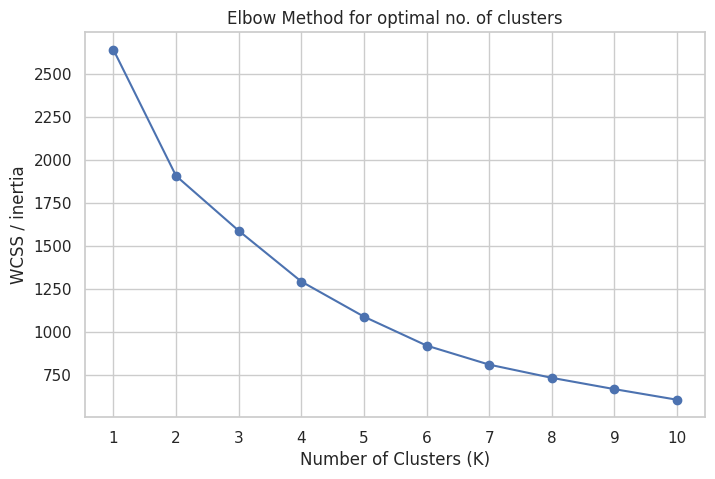

In [20]:
wcss=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS / inertia')
plt.title('Elbow Method for optimal no. of clusters')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [21]:
silhouette_values=[]

for k in range(2,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(X_scaled)
    score=silhouette_score(X_scaled,labels)
    silhouette_values.append(score)

silhouette_table=pd.DataFrame({'Number of Clusters':range(2,11),'Silhouette Score':silhouette_values})
display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.3735
1,3,0.3757
2,4,0.3779
3,5,0.3920
4,6,0.4011
5,7,0.4028
6,8,0.3982
7,9,0.4025
8,10,0.4125


In [22]:
suggested_k=int(
    silhouette_table.loc[silhouette_table['Silhouette Score'].idxmax(),'Number of Clusters']
)
print("K Suggested by the highest silhouette score ",suggested_k)

K Suggested by the highest silhouette score  10


In [23]:
K= suggested_k
kmeans_model=KMeans(n_clusters=K,random_state=42,n_init=10)
kmeans_lables=kmeans_model.fit_predict(X_scaled)

In [24]:
df_kmeans=df.copy()
df_kmeans["K-Means_Cluster"]=kmeans_lables
print("K-Means clustering completed")
print("Number of customers in each cluster:")
print(df_kmeans["K-Means_Cluster"].value_counts().sort_index())

print("Sample records with cluster lables:")
display(df_kmeans.head())

K-Means clustering completed
Number of customers in each cluster:
K-Means_Cluster
0     88
1     74
2    149
3      3
4     36
5     32
6     22
7     27
8      5
9      4
Name: count, dtype: int64
Sample records with cluster lables:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,K-Means_Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,4
4,2,3,22615,5410,7198,3915,1777,5185,0


In [26]:
hierarchical_model=AgglomerativeClustering(n_clusters=K,metric='euclidean',linkage='ward')
hierarchical_labels=hierarchical_model.fit_predict(X_scaled)

In [27]:
df_hierarchical=df.copy()
df_hierarchical["Hierarchical_Cluster"]=hierarchical_labels

print("Hierarchical clustering completed")
print("Number of customers in each cluster:")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())

print("Sample records with cluster lables:")
display(df_hierarchical.head())

Hierarchical clustering completed
Number of customers in each cluster:
Hierarchical_Cluster
0     19
1     40
2     91
3     14
4      4
5      3
6     74
7     62
8     33
9    100
Name: count, dtype: int64
Sample records with cluster lables:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,2


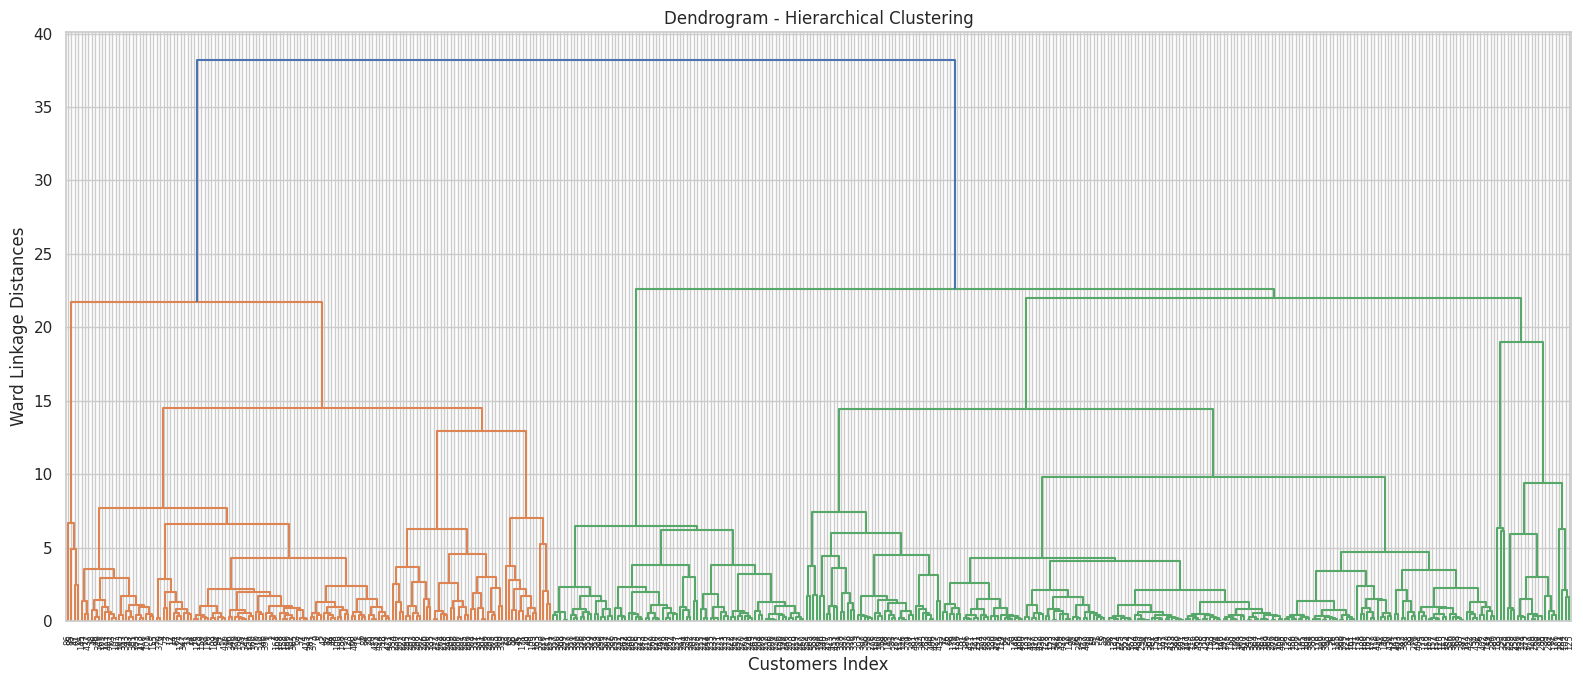

In [28]:
Z=linkage(X_scaled,method="ward",metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)

plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customers Index")
plt.ylabel("Ward Linkage Distances")
plt.tight_layout()
plt.show()

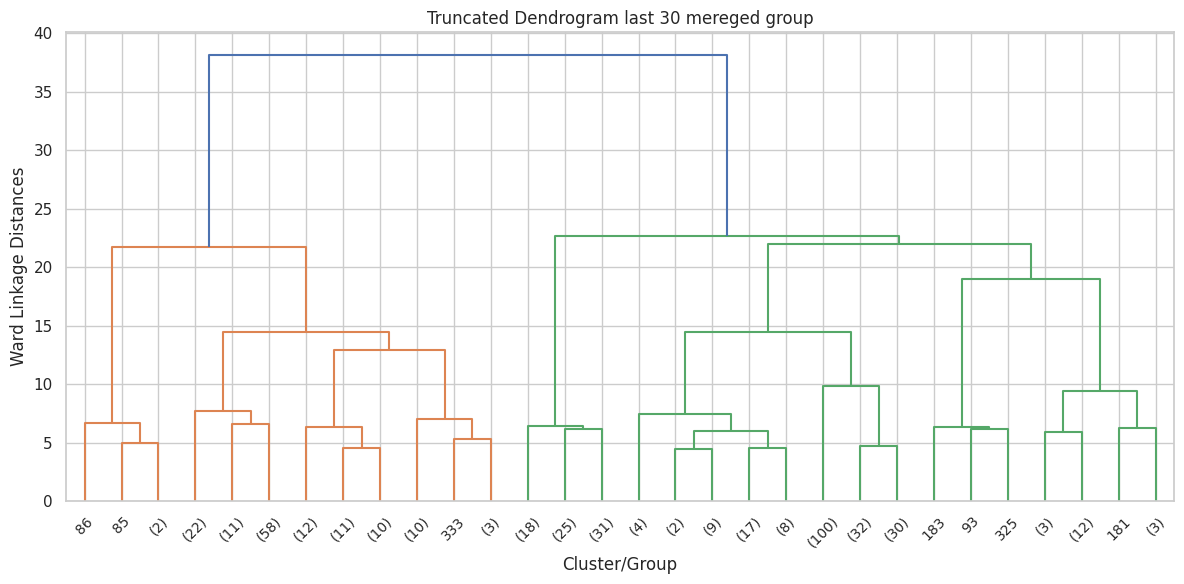

In [30]:
#Truncated dendrogram for easier interpretation
plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode="lastp",p=30,show_leaf_counts=True,leaf_rotation=45)

plt.title("Truncated Dendrogram last 30 mereged group")
plt.xlabel("Cluster/Group")
plt.ylabel("Ward Linkage Distances")
plt.tight_layout()
plt.show()

In [31]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print("Varience explained by the two PCA component:",
      round(pca.explained_variance_ratio_.sum()*100,2),
      "%"
)
plot_df=pd.DataFrame({"PC1":X_pca[:,0],"PC2":X_pca[:,1],"KMeans_cluster":kmeans_lables.astype(str),"Hierarchical_Cluster":hierarchical_labels.astype(str)})

Varience explained by the two PCA component: 60.92 %


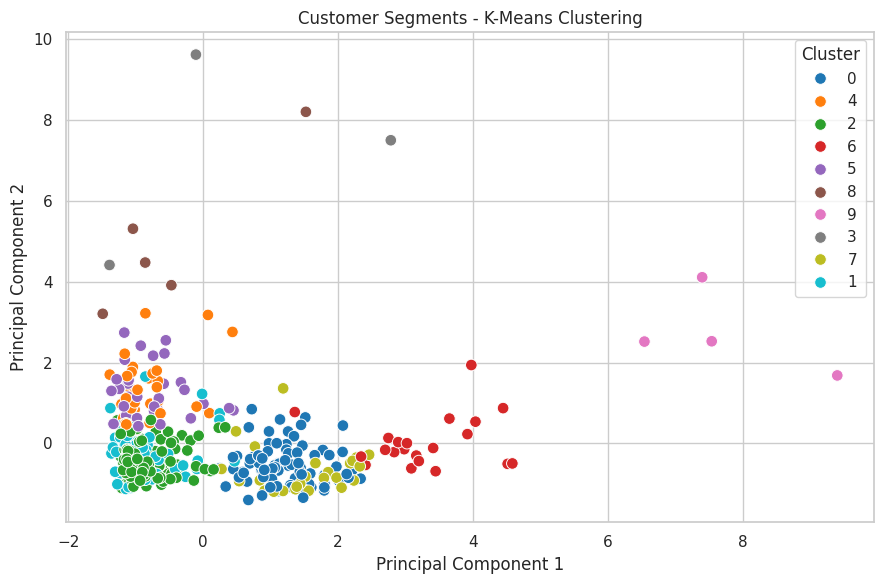

In [34]:
#K-Means visualization
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df,x="PC1",y="PC2",hue="KMeans_cluster",palette="tab10",s=70)
plt.title("Customer Segments - K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [35]:
#Function to cal clustering evaluation metrics
def evaluate_clustering(X_data, labels,model_name):
  return{
      "Algorithm":model_name,
      "Number of Clusters":len(np.unique(labels)),
      "Silhouette Score":silhouette_score(X_data,labels)}

In [36]:
#Eval both models using the same scaled features
comparison=pd.DataFrame(evaluate_clustering(X_scaled,kmeans_lables,"K-Means"),
                        evaluate_clustering(X_scaled,hierarchical_labels,"Hierarchical Clustering"))

print("Comparision of different Clustoring Algorithm :")
display(comparison.round(4))

Comparision of different Clustoring Algorithm :


,Algorithm,Number of Clusters,Silhouette Score
Algorithm,K-Means,10,0.4125
Number of Clusters,K-Means,10,0.4125
Silhouette Score,K-Means,10,0.4125
